# Flipkart Mobile Review Scrapping 

# Scraping a single page

#### open webpage in a new tab

In [1]:

#Allows you to open URLs in a web browser directly from Python
import webbrowser 

# URL to open
url = "https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off"

# Path to Chrome executable (Windows default path)
chrome_path = "C:/Program Files/Google/Chrome/Application/chrome.exe %s"

# Register and open the URL in Chrome
webbrowser.get(chrome_path).open(url)


True

#### Loading the WebPage in Memory using requests library

In [2]:

#send HTTP requests to fetch data from web pages/APIs.
import requests  

# The web address from which we want to retrieve data.
url = "https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off"

#Additional information sent to the server
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0 Safari/537.36"
}

#stores the server’s reply after making the request
response = requests.get(url,headers=headers) 

# get the webpage
response 


<Response [200]>

In [3]:

# Note -->  realted success(2xx) - Redirection errors(3xx)  - Client Errors(4xx) - Server Errors(5xx)

# checking the status code
response.status_code 


200

In [4]:
webpage=response.text  # Extact the html code of the webpages

In [5]:

#Used to parse and extract data from HTML or XML pages.
from bs4 import BeautifulSoup  

# parse(taking raw data) of html and make it in readable format and store it in soup 
soup = BeautifulSoup(webpage,"html.parser")  


#### Extracting Data using find_all()

In [6]:

# from the nested div extracting the data from the first container 
# find_all() searches the HTML tree for all matching elements.

all_containers = soup.find_all("div",class_="jIjQ8S")  


In [7]:
import numpy as np                 #numerical computations and arrays
import re                          #Provides regular expressions for pattern matching in text.
                         
#features
mobile_list=[]
ratings_list=[]
ram_list=[]
screen_size_list=[]
rear_cam_list=[]
battery_list=[]
price_list=[]

 # from the nested div extracting the data from all containers 
for container in all_containers:
    
    # ".find()" searches inside container for the first HTML tag that matches
    prices = container.find("div", class_="hZ3P6w DeU9vF").text
    price_list.append(prices)
     
    mobiles = container.find("div", class_="RG5Slk").text
    mobile_list.append(mobiles) 
    
    star = container.find("div", class_="MKiFS6")
    if star:
        ratings_list.append(star.text)
    else:
        ratings_list.append(None)

    # "re.findall" finds all occurrences of a pattern in a string and returns them as a list
    ram = re.findall(r"(\d+)\s*GB\s*RAM", container.text)
    ram_list.append(int(ram[0]) if ram else None)

    display = re.findall(r"\((\d+\.?\d+)\s*inch\)", container.text)
    screen_size_list.append(float(display[0]) if display else None)
    
    rear_cam = re.findall(r"(\d+)MP(?:\s*\([^)]*\))?", container.text)
    rear_cam_list.append(int(rear_cam[0]) if rear_cam else None)
    
    battery = re.findall(r"(\d+)\s*mAh", container.text)
    battery_list.append(int(battery[0]) if battery else None)
    

In [8]:

#Used for data manipulation and analysis using DataFrames
import pandas as pd                

# assigning all the values
df=pd.DataFrame({"Mobile":mobile_list,"Ratings":ratings_list,"Ram":ram_list,"Screen_size":screen_size_list,"Rear_cam":rear_cam_list,"Battery":battery_list,"Price":price_list})


In [9]:
df

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
0,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,"₹8,999"
1,"Nothing Phone (4b) (Black, 128 GB)",4.4,6.0,6.770,50,6000.0,"₹29,999"
2,"MOTOROLA g06 power (Pantone tapestry, 64 GB)",4.1,4.0,6.880,50,7000.0,"₹11,999"
3,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,6.0,6.760,50,7200.0,"₹27,999"
4,"BOLTT ACE 5G (Midnight Black, 64 GB)",4.1,4.0,6.790,64,6000.0,"₹11,999"
5,"Samsung Galaxy S25 5G Snapdragon (Navy, 128 GB)",4.6,12.0,6.200,50,4000.0,"₹54,999"
6,"Nokia 105 Classic Single Sim Keypad Phone, Wit...",4,NaN,1.770,0,800.0,₹999
7,"Ai+ Pulse 2 (Pink, 64 GB)",4.1,4.0,6.745,50,6000.0,"₹8,999"
8,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)",4.4,8.0,6.700,50,5000.0,"₹24,999"
9,"REDMI A7 Pro 5G (Black, 64 GB)",3.9,4.0,6.900,32,6300.0,"₹14,295"


In [10]:
df.isnull().sum() # checking for the null values

Mobile         0
Ratings        0
Ram            2
Screen_size    0
Rear_cam       0
Battery        1
Price          0
dtype: int64

In [11]:
df[df.isnull().any(axis=1)] # it's a keypad mobile with 32 MB RAM 

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
6,"Nokia 105 Classic Single Sim Keypad Phone, Wit...",4,NaN,1.77,0,800.0,₹999
18,"Apple iPhone 17 (Black, 256 GB)",4.6,NaN,6.30,48,NaN,"₹97,300"


In [12]:
df[df["Rear_cam"]==0]

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
6,"Nokia 105 Classic Single Sim Keypad Phone, Wit...",4,NaN,1.77,0,800.0,₹999


In [13]:
df['Rear_cam'].unique()

array([50, 64,  0, 32, 48])

# Multi-Page scraping

In [14]:
mobile_list=[]
ratings_list=[]
ram_list=[]
screen_size_list=[]
rear_cam_list=[]
battery_list=[]
price_list=[]

for i in range(1,10):
    url=f"https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page={i}"
    response=requests.get(url, headers=headers)
    soup=BeautifulSoup(response.text, "html.parser")
    all_containers = soup.find_all("div", class_="jIjQ8S")

    for container in all_containers:

        prices = container.find("div", class_="hZ3P6w DeU9vF")
        mobiles = container.find("div", class_="RG5Slk")
        star = container.find("div", class_="MKiFS6")

        ram = re.findall(r"(\d+)\s*GB\s*RAM", container.text)
        display = re.findall(r"\((\d+\.?\d+)\s*inch\)", container.text)
        rear_cam = re.findall(r"(\d+)MP(?:\s*\([^)]*\))?", container.text)
        battery = re.findall(r"(\d+)\s*mAh", container.text)

        price_list.append(prices.text if prices else np.nan)
        mobile_list.append(mobiles.text if mobiles else np.nan)

        battery_list.append(int(battery[0]) if battery else np.nan)
        rear_cam_list.append(int(rear_cam[0]) if rear_cam else np.nan)
        screen_size_list.append(float(display[0]) if display else np.nan)
        ram_list.append(int(ram[0]) if ram else np.nan)

        if star:
            ratings_list.append(star.text.strip())
        else:
            ratings_list.append(np.nan)


In [15]:
df=pd.DataFrame({"Mobile":mobile_list,"Ratings":ratings_list,"Ram":ram_list,"Screen_size":screen_size_list,"Rear_cam":rear_cam_list,"Battery":battery_list,"Price":price_list})

In [16]:
df

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
0,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,"₹8,999"
1,"Nothing Phone (4b) (Black, 128 GB)",4.4,6.0,6.770,50,6000.0,"₹29,999"
2,"MOTOROLA g06 power (Pantone tapestry, 64 GB)",4.1,4.0,6.880,50,7000.0,"₹11,999"
3,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,6.0,6.760,50,7200.0,"₹27,999"
4,"BOLTT ACE 5G (Midnight Black, 64 GB)",4.1,4.0,6.790,64,6000.0,"₹11,999"
...,...,...,...,...,...,...,...
211,"Google Pixel 11 (Pistachio, 256 GB)",4.5,12.0,6.300,48,4985.0,"₹89,999"
212,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,4.6,12.0,6.200,50,4000.0,"₹54,999"
213,"Ai+ Nova 2 5G (Blue, 64 GB)",4.2,4.0,6.745,50,6000.0,"₹13,999"
214,"Samsung Galaxy A36 5G (Awesome Lavender, 256 GB)",4.4,8.0,6.700,50,5000.0,"₹29,499"


In [19]:
df.head()

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
0,Rastic SM Guru Music 2 Mobile Phone,3.4,NaN,2.50,0.0,850.0,₹910
1,"POCO C71 (Desert Gold, 64 GB)",3.8,4.0,6.88,32.0,5200.0,"₹6,199"
2,"MOTOROLA Edge 60 Pro (Pantone Shadow, 256 GB)",4.3,12.0,6.70,50.0,6000.0,"₹31,999"
3,"POCO C71 (Cool Blue, 128 GB)",4.1,6.0,6.88,32.0,5200.0,"₹6,799"
4,"REDMI Note 14 SE 5G (Crimson Art, 128 GB)",4.3,6.0,6.67,50.0,5110.0,"₹13,499"


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216 entries, 0 to 215
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Mobile       216 non-null    object 
 1   Ratings      216 non-null    object 
 2   Ram          211 non-null    float64
 3   Screen_size  210 non-null    float64
 4   Rear_cam     216 non-null    int64  
 5   Battery      212 non-null    float64
 6   Price        216 non-null    object 
dtypes: float64(3), int64(1), object(3)
memory usage: 11.9+ KB


In [18]:
# total null values
df.isnull().sum()

Mobile         0
Ratings        0
Ram            5
Screen_size    6
Rear_cam       0
Battery        4
Price          0
dtype: int64

In [19]:
df[df.isnull().any(axis=1)]

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
6,"Nokia 105 Classic Single Sim Keypad Phone, Wit...",4,NaN,1.77,0,800.0,₹999
13,"realme P4 Lite 5G (Mosaic Blue, 128 GB)",4.2,4.0,NaN,13,7000.0,"₹17,499"
18,"Apple iPhone 17 (Black, 256 GB)",4.6,NaN,6.30,48,NaN,"₹97,300"
44,"realme P4 Lite 5G (Mosaic Green, 128 GB)",4.2,4.0,NaN,13,7000.0,"₹17,499"
74,"realme P4 Lite 5G (Mosaic Blue, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
94,"Samsung Galaxy F07 (Green, 64 GB)",4.2,4.0,NaN,50,5000.0,"₹11,999"
123,"realme P4 Lite 5G (Mosaic Green, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
124,"realme P4 Lite 5G (Mosaic Blue, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
162,"Apple iPhone 18 Pro (Burgundy, 256 GB)",4.6,NaN,6.30,48,NaN,"₹1,64,900"
184,"Apple iPhone 15 (Blue, 128 GB)",4.6,NaN,6.10,48,NaN,"₹69,999"


In [20]:
df["Company"]=df["Mobile"].str.split().str[0].str.upper()

In [21]:
df[df["Company"]=="APPLE"].iloc[0]

Mobile         Apple iPhone 17 (Black, 256 GB)
Ratings                                    4.6
Ram                                        NaN
Screen_size                                6.3
Rear_cam                                    48
Battery                                    NaN
Price                                  ₹97,300
Company                                  APPLE
Name: 18, dtype: object

In [23]:
import requests
from bs4 import BeautifulSoup
import re
import numpy as np

# features 
mobile_list=[]
ratings_list=[]
ram_list=[]
screen_size_list=[]
rear_cam_list=[]
battery_list=[]
price_list=[]

# header 
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0 Safari/537.36"
}

for i in range(1,14):
    url=f"https://www.flipkart.com/search?q=mobiles&otracker=search&otracker1=search&marketplace=FLIPKART&as-show=on&as=off&page={i}"
    response=requests.get(url,headers=headers)
    webpage=response.text
    soup=BeautifulSoup(webpage,"html.parser")
    all_containers=soup.find_all("div",class_="jIjQ8S")

    for container in all_containers:
        prices=container.find("div",class_="hZ3P6w DeU9vF")
        mobiles=container.find("div",class_="RG5Slk")
        star=container.find("div",class_="MKiFS6")

        ram=re.findall(r"(\d+)\s*GB\s*RAM",container.text)

        # capture both inch & cm inside parentheses
        display=re.findall(r"\((\d+\.?\d+)\s*(inch|cm)\)",container.text)

        rear_cam=re.findall(r"(\d+)MP(?:\s*\([^)]*\))?",container.text)
        battery=re.findall(r"(\d+)\s*mAh",container.text)

        # ---- Append safely ----
        if prices:
            price_list.append(prices.text)
        else:
            price_list.append(np.nan)

        if mobiles:
            mobile_list.append(mobiles.text)
        else:
            mobile_list.append(np.nan)

        if battery:
            battery_list.append(int(battery[0]))
        else:
            battery_list.append(np.nan)

        if rear_cam:
            rear_cam_list.append(int(rear_cam[0]))
        else:
            rear_cam_list.append(np.nan)

        # Handle display (convert cm → inch if needed)
        if display:
            size, unit = display[0]   # first match (value, unit)
            size = float(size)
            if unit == "cm":
                size = size / 2.54    # convert cm to inches
            screen_size_list.append(size)
        else:
            screen_size_list.append(np.nan)

        if ram:
            ram_list.append(int(ram[0]))
        else:
            ram_list.append(np.nan)

        if star:
            ratings_list.append(star.text)
        else:
            ratings_list.append(np.nan)


In [24]:
df=pd.DataFrame({"Mobile":mobile_list,"Ratings":ratings_list,"Ram":ram_list,"Screen_size":screen_size_list,"Rear_cam":rear_cam_list,"Battery":battery_list,"Price":price_list})

In [25]:
df

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
0,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,"₹8,999"
1,"Nothing Phone (4b) (Black, 128 GB)",4.4,6.0,6.770,50,6000.0,"₹29,999"
2,"MOTOROLA g06 power (Pantone tapestry, 64 GB)",4.1,4.0,6.880,50,7000.0,"₹11,999"
3,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,6.0,6.760,50,7200.0,"₹27,999"
4,"Samsung Galaxy S25 5G Snapdragon (Navy, 128 GB)",4.6,12.0,6.200,50,4000.0,"₹54,999"
...,...,...,...,...,...,...,...
307,"Google Pixel 11 (Obsidian, 256 GB)",4.5,12.0,6.300,48,4985.0,"₹89,999"
308,"Nothing Phone (4a) Pro (Black, 256 GB)",4.6,12.0,6.830,50,5400.0,"₹59,999"
309,"Google Pixel 10 (Frost, 256 GB)",4.5,12.0,6.300,48,4970.0,"₹74,999"
310,"Google Pixel 11 (Hibiscus, 256 GB)",4.5,12.0,6.300,48,4985.0,"₹89,999"


In [26]:
df.shape

(312, 7)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Mobile       312 non-null    object 
 1   Ratings      312 non-null    object 
 2   Ram          304 non-null    float64
 3   Screen_size  303 non-null    float64
 4   Rear_cam     312 non-null    int64  
 5   Battery      305 non-null    float64
 6   Price        312 non-null    object 
dtypes: float64(3), int64(1), object(3)
memory usage: 17.2+ KB


In [28]:
df.isnull().sum()

Mobile         0
Ratings        0
Ram            8
Screen_size    9
Rear_cam       0
Battery        7
Price          0
dtype: int64

In [29]:
df[df.isnull().any(axis=1)]

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
6,"Nokia 105 Classic Single Sim Keypad Phone, Wit...",4,NaN,1.77,0,800.0,₹999
13,"realme P4 Lite 5G (Mosaic Blue, 128 GB)",4.2,4.0,NaN,13,7000.0,"₹17,499"
18,"Apple iPhone 17 (Black, 256 GB)",4.6,NaN,6.30,48,NaN,"₹97,300"
79,"realme P4 Lite 5G (Mosaic Blue, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
83,"realme P4 Lite 5G (Mosaic Green, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
119,"realme P4 Lite 5G (Mosaic Blue, 128 GB)",4.2,6.0,NaN,13,7000.0,"₹21,999"
122,"Apple iPhone 17 (Mist Blue, 256 GB)",4.6,NaN,6.30,48,NaN,"₹97,300"
125,"realme P4 Lite 5G (Mosaic Green, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
128,"realme P4 Lite 5G (Mosaic Blue, 64 GB)",4.2,4.0,NaN,13,7000.0,"₹15,999"
154,"Apple iPhone 18 Pro (Burgundy, 256 GB)",4.6,NaN,6.30,48,NaN,"₹1,64,900"


In [30]:
df.dropna(inplace=True) # dropping the null values

In [31]:
df

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price
0,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,"₹8,999"
1,"Nothing Phone (4b) (Black, 128 GB)",4.4,6.0,6.770,50,6000.0,"₹29,999"
2,"MOTOROLA g06 power (Pantone tapestry, 64 GB)",4.1,4.0,6.880,50,7000.0,"₹11,999"
3,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,6.0,6.760,50,7200.0,"₹27,999"
4,"Samsung Galaxy S25 5G Snapdragon (Navy, 128 GB)",4.6,12.0,6.200,50,4000.0,"₹54,999"
...,...,...,...,...,...,...,...
307,"Google Pixel 11 (Obsidian, 256 GB)",4.5,12.0,6.300,48,4985.0,"₹89,999"
308,"Nothing Phone (4a) Pro (Black, 256 GB)",4.6,12.0,6.830,50,5400.0,"₹59,999"
309,"Google Pixel 10 (Frost, 256 GB)",4.5,12.0,6.300,48,4970.0,"₹74,999"
310,"Google Pixel 11 (Hibiscus, 256 GB)",4.5,12.0,6.300,48,4985.0,"₹89,999"


In [32]:
df["Price"]=df['Price'].str.replace("₹","").str.replace(",","").astype(float)

In [33]:
df["Company"]=df["Mobile"].str.split().str[0].str.upper()

In [34]:
# clean Ratings: convert to float (ignore missing values)
df["Ratings"] = pd.to_numeric(df["Ratings"], errors="coerce")


In [36]:
df

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price,Company
0,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,8999.0,BOLTT
1,"Nothing Phone (4b) (Black, 128 GB)",4.4,6.0,6.770,50,6000.0,29999.0,NOTHING
2,"MOTOROLA g06 power (Pantone tapestry, 64 GB)",4.1,4.0,6.880,50,7000.0,11999.0,MOTOROLA
3,"vivo T5x 5G (Cosmic Green, 128 GB)",4.4,6.0,6.760,50,7200.0,27999.0,VIVO
4,"Samsung Galaxy S25 5G Snapdragon (Navy, 128 GB)",4.6,12.0,6.200,50,4000.0,54999.0,SAMSUNG
...,...,...,...,...,...,...,...,...
307,"Google Pixel 11 (Obsidian, 256 GB)",4.5,12.0,6.300,48,4985.0,89999.0,GOOGLE
308,"Nothing Phone (4a) Pro (Black, 256 GB)",4.6,12.0,6.830,50,5400.0,59999.0,NOTHING
309,"Google Pixel 10 (Frost, 256 GB)",4.5,12.0,6.300,48,4970.0,74999.0,GOOGLE
310,"Google Pixel 11 (Hibiscus, 256 GB)",4.5,12.0,6.300,48,4985.0,89999.0,GOOGLE


# Exploratory Data Analysis

#### *Basic Stats*

In [37]:
import matplotlib.pyplot as plt    #creating visualizations and plots
import seaborn as sns              #A statistical plotting library for high-level visualizations

In [38]:
print("Total number of mobiles:", len(df))
print("Average Price:", df['Price'].mean())
print("Minimum Price:", df['Price'].min())
print("Maximum Price:", df['Price'].max())
print("Company with most mobiles:")
print(df['Company'].value_counts().head())

Total number of mobiles: 295
Average Price: 40427.52542372881
Minimum Price: 8999.0
Maximum Price: 94999.0
Company with most mobiles:
Company
SAMSUNG     77
GOOGLE      58
AI+         29
VIVO        22
MOTOROLA    20
Name: count, dtype: int64


In [40]:
df[df["Price"]==8999.0]

,Mobile,Ratings,Ram,Screen_size,Rear_cam,Battery,Price,Company
0,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,8999.0,BOLTT
7,"Ai+ Pulse 2 (Pink, 64 GB)",4.1,4.0,6.745,50,6000.0,8999.0,AI+
21,"Ai+ Pulse 2 FE (Blue, 64 GB)",4.2,4.0,6.670,50,5000.0,8999.0,AI+
22,"Ai+ Pulse 2 FE (Purple, 64 GB)",4.2,4.0,6.670,50,5000.0,8999.0,AI+
23,"Ai+ Pulse 2 FE (Black, 64 GB)",4.2,4.0,6.670,50,5000.0,8999.0,AI+
26,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,8999.0,BOLTT
50,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,8999.0,BOLTT
53,"Ai+ Pulse 2 (Black, 64 GB)",4.1,4.0,6.745,50,6000.0,8999.0,AI+
76,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,8999.0,BOLTT
96,"BOLTT EVO (Arctic White, 64 GB)",4.1,4.0,6.790,50,6000.0,8999.0,BOLTT


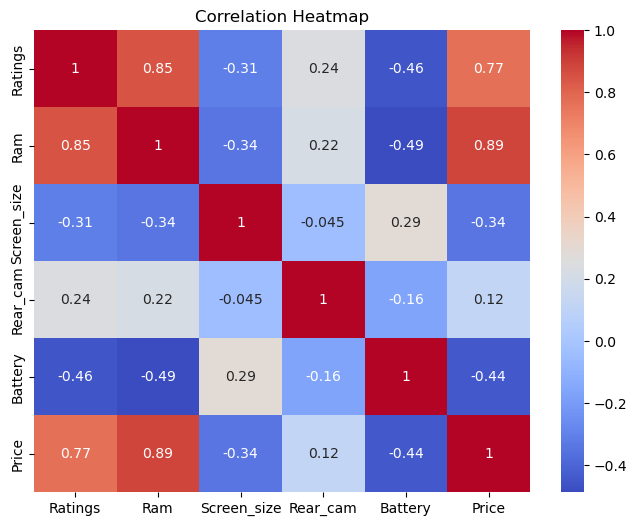

In [41]:
# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## *Univariate Analysis*

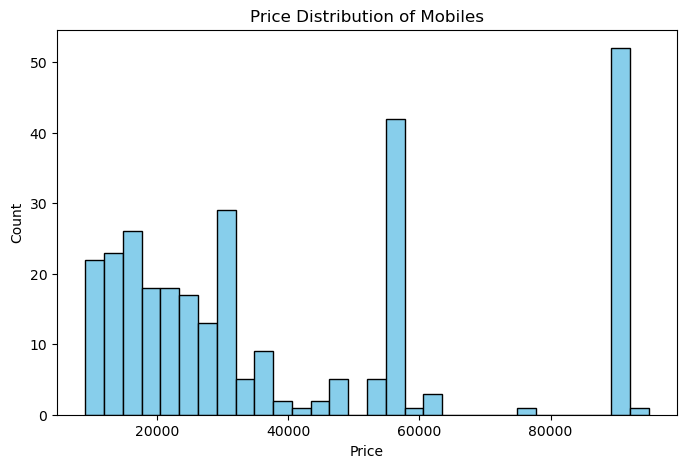

In [42]:
# Histogram of Prices
plt.figure(figsize=(8,5))
plt.hist(df['Price'], bins=30, color='skyblue', edgecolor='black')
plt.title('Price Distribution of Mobiles')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

## Count plot of companies

C:\Users\ruqua\AppData\Local\Temp\ipykernel_19148\2366567024.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df['Company'], order=df['Company'].value_counts().index, palette='viridis')


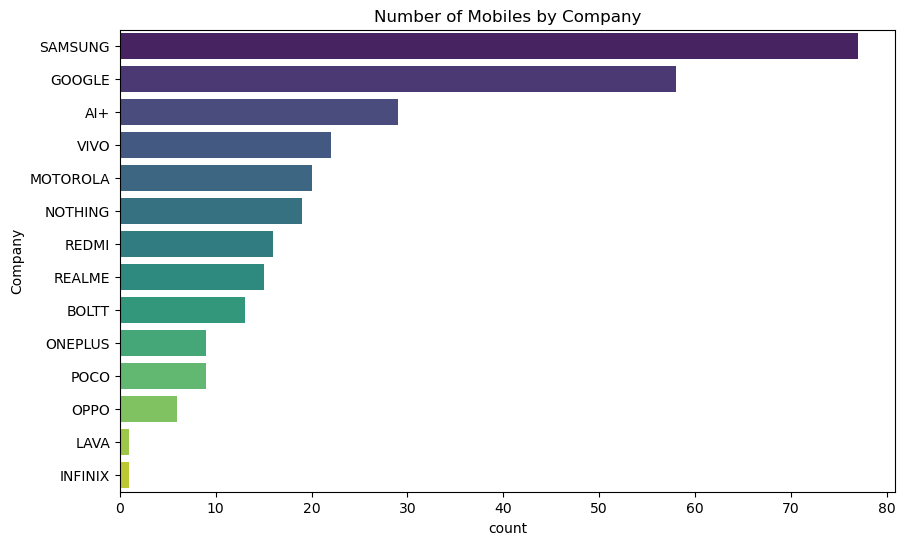

In [43]:
# Countplot of Companies
plt.figure(figsize=(10,6))
sns.countplot(y=df['Company'], order=df['Company'].value_counts().index, palette='viridis')
plt.title('Number of Mobiles by Company')
plt.show()

## Boxplot of Prices

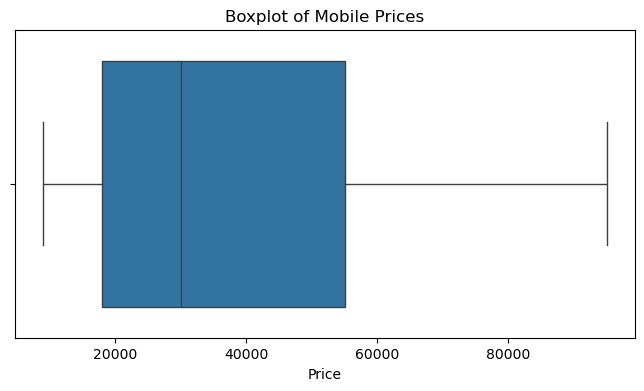

In [44]:
# Boxplot of Prices
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Price'])
plt.title('Boxplot of Mobile Prices')
plt.show()

# Scatter plot Price vs RAM

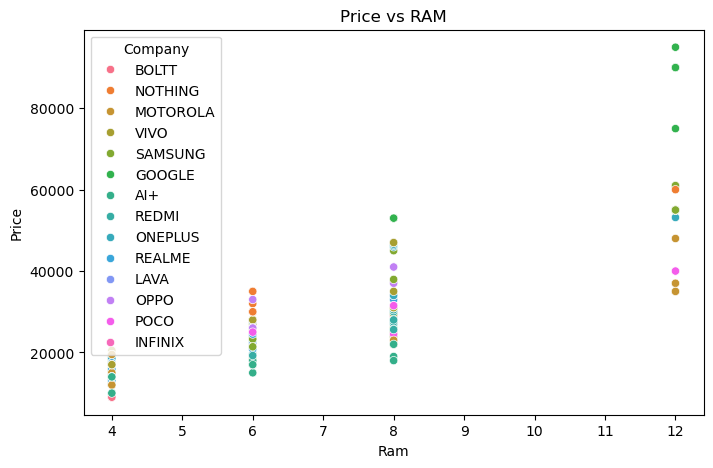

In [45]:

plt.figure(figsize=(8,5))
sns.scatterplot(x=df['Ram'], y=df['Price'], hue=df['Company'])
plt.title('Price vs RAM')
plt.show()

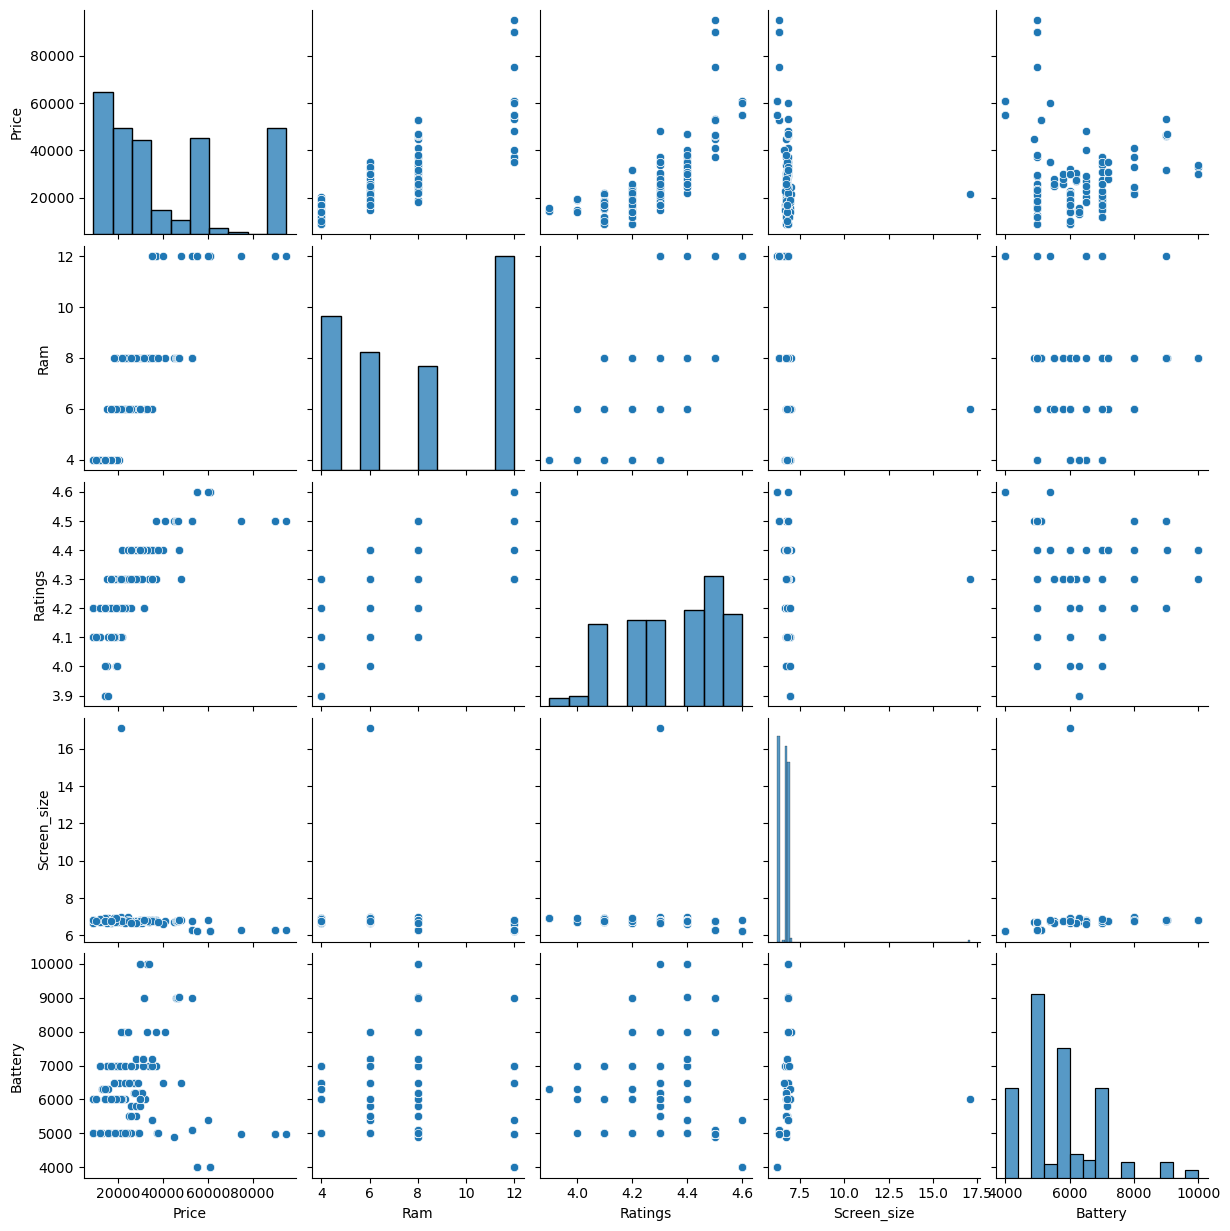

In [46]:
sns.pairplot(df[['Price','Ram','Ratings','Screen_size','Battery']])
plt.show()

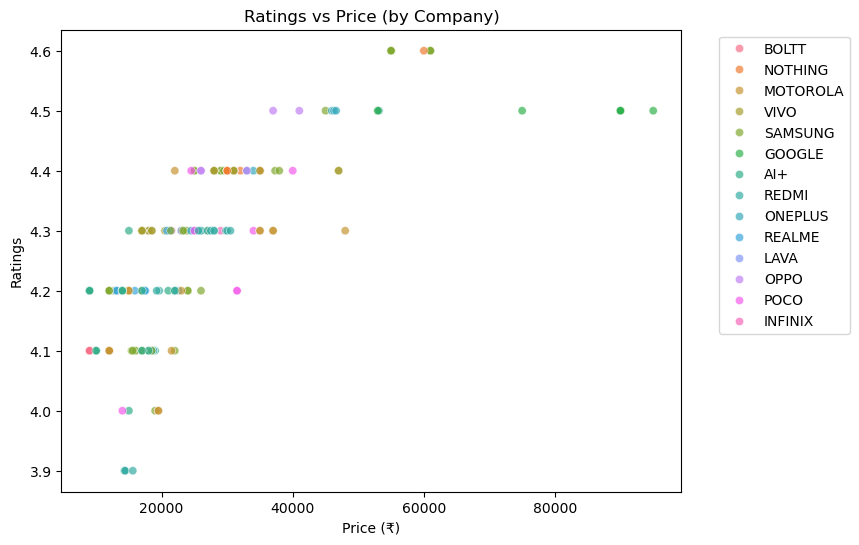

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="Price", y="Ratings", hue="Company", alpha=0.7)

plt.title("Ratings vs Price (by Company)")
plt.xlabel("Price (₹)")
plt.ylabel("Ratings")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # move legend outside
plt.show()


## Conclusion

1) MOTOROLA,POCO,SAMSUNG ,INFINIX ,REALME dominate the listings
2) Price distribution shows a concentration in mid-range devices.
3) RAM and Price are positively correlated.
4) Battery size seems fairly consistent across prices.
5) Outliers exist in our data and with very high-end mobiles with high prices.